# Importing data from Eyelink EDF files

In [1]:
import pypillometry as pp
from pypillometry import u
import matplotlib.pyplot as plt

The easiest way is to use a local filename or a URL where the EDF file is stored:

pp: 14:36:37 | INFO     | fetch_url:462 | Downloading 'https://osf.io/trsuq/download' to /tmp/pypillometry_80ga7xxe/download


download:   0%|          | 0.00/14.2M [00:00<?, ?iB/s]

download:   1%|          | 111k/14.2M [00:00<00:18, 810kiB/s]

download:   2%|▏         | 305k/14.2M [00:00<00:10, 1.35MiB/s]

download:   4%|▎         | 513k/14.2M [00:00<00:08, 1.66MiB/s]

download:   5%|▌         | 737k/14.2M [00:00<00:07, 1.86MiB/s]

... (22 outputs left out)

download: 100%|██████████| 14.2M/14.2M [00:02<00:00, 5.23MiB/s]


pp: 14:36:42 | INFO     | _read_edf:730 | Loading EDF file: /tmp/pypillometry_80ga7xxe/download (current log level: INFO, set to DEBUG to see eyelinkio output)


pp: 14:36:48 | INFO     | local_copy:525 | Deleting downloaded copy: /tmp/pypillometry_80ga7xxe


pp: 14:36:48 | INFO     | from_eyelink:1639 | Filtering out Eyelink triggers


EyeData(download, 41.3MiB):
 n                 : 598885
 sampling_rate     : 500.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'left_pupil', 'right_x', 'right_y', 'right_pupil']
 nevents           : 1322
 experimental_setup: {'screen_resolution': (1280, 1024), 'physical_screen_size_mm': None, 'eye_to_screen_distance_mm': 'not set', 'camera_position': 'not set'}
 calibration       : {'left': {'n': 9, 'mean': 0.4344, 'sd': 0.2242, 'max': 0.79, 'min': 0.05}, 'right': {'n': 9, 'mean': 0.33, 'sd': 0.1056, 'max': 0.5, 'min': 0.16}}
 duration_minutes  : 19.9628
 start_min         : 0.0
 end_min           : 19.9628
 params            : {}
 nblinks           : {}
 blinks            : {}
 glimpse           : EyeDataDict(vars=6,n=598885,shape=(598885,)): 
  left_x (float64): 668.2, 660.6, 650.0, 639.1, 628.4...
  left_y (float64): 491.1, 490.1, 489.4, 488.5, 488.0...
  left_pupil (float64): 724.0, 724.0, 725.0, 727.0, 727.0...
  right_x (float64): 682.8, 679.5, 674.5, 662.7, 644.3...
  right_y (float64): 505.2, 502.9, 501.3, 499.0, 496.4...
  right_pupil (float64): 637.0, 642.0, 644.0, 639.0, 636.0...

 Info: 1 keys: eyelink_info
 History:
 *
 └ set_events(Events: 1322 events | units=ms)
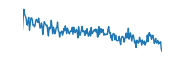
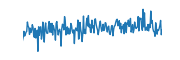
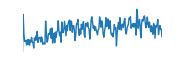
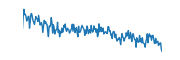
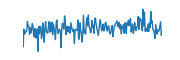
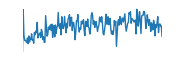

In [2]:
url = "https://osf.io/trsuq/download"  # will download the file from OSF
d = pp.EyeData.from_eyelink(url)
d

You can also keep a local copy of the file to avoid repeated downloads. The following command downloads the file only the first time and reads the local file afterwards:

In [3]:
d = pp.EyeData.from_eyelink(url, cache_file="example_data/test.edf")

pp: 14:36:49 | INFO     | fetch_url:448 | Using cached copy of 'https://osf.io/trsuq/download': example_data/test.edf


pp: 14:36:49 | INFO     | _read_edf:730 | Loading EDF file: example_data/test.edf (current log level: INFO, set to DEBUG to see eyelinkio output)


pp: 14:37:00 | INFO     | from_eyelink:1639 | Filtering out Eyelink triggers


Reading EDF files is relatively slow. If you work with the same file repeatedly, save the `EyeData` object with `d.write_file("file.pd")` and load it with `pp.EyeData.from_file("file.pd")` (see the end of the [ASC notebook](importdata_asc.ipynb)), or convert it on the command line with `edf2pypil`.

This works for publicly shared EDF files such as the one under <https://osf.io/trsuq/download> (this file is also available as the example dataset `"rlmw_010_edf"`, see [example datasets](example_datasets.ipynb)). If you want to load data from a private OSF repository, you need to authenticate first. To do that, create a "Personal access token" on your OSF page under <https://osf.io/settings/tokens>.

Copy that token and store it in a variable or a protected file (CAUTION: anybody who has that token can access your private OSF data). Here, the token is stored in a file "my_osf_token.secret" so that it does not appear in the documentation:

In [4]:
private_url = "https://osf.io/5vkj3/download"

# read the token from the file
with open("my_osf_token.secret") as f:
    token = f.read().strip()

# use the token to authenticate to OSF
session = pp.osf_authenticate(token, validate=True)
d = pp.EyeData.from_eyelink(private_url, session=session, cache_file="example_data/private.edf")

pp: 14:37:00 | INFO     | osf_authenticate:104 | OSF token validation succeeded.


pp: 14:37:00 | INFO     | fetch_url:448 | Using cached copy of 'https://osf.io/5vkj3/download': example_data/private.edf


pp: 14:37:00 | INFO     | _read_edf:730 | Loading EDF file: example_data/private.edf (current log level: INFO, set to DEBUG to see eyelinkio output)


pp: 14:37:33 | INFO     | from_eyelink:1639 | Filtering out Eyelink triggers


The result is an `EyeData` object containing all the samples and events. Here we plot the pupil data for minutes 10-11. Plot ranges (and most other times in `pypillometry`) can be given with units, either by multiplying with a unit from `pp.u` or as a string such as `("10 min", "11 min")`:

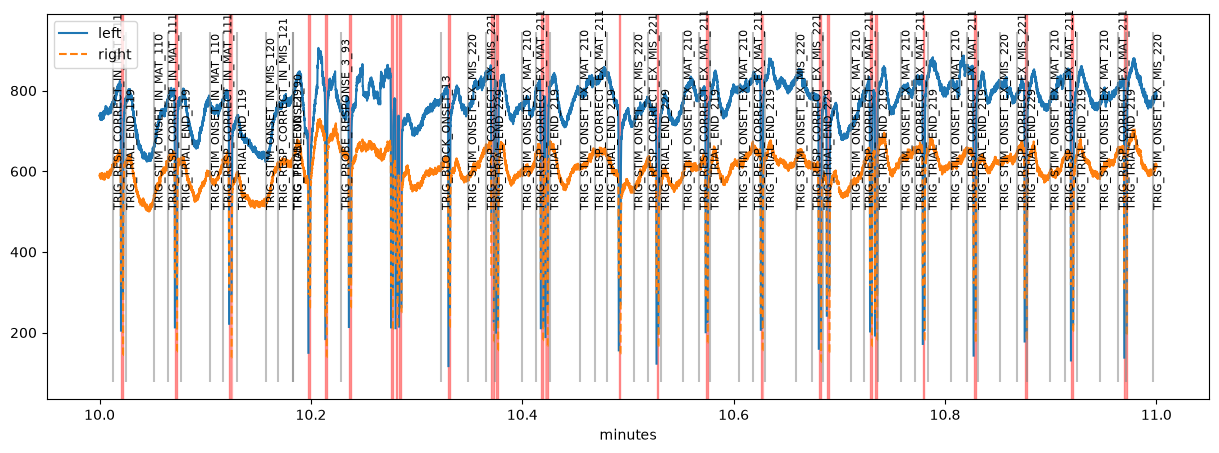

In [5]:
plt.figure(figsize=(15, 5))
d.plot.plot_pupil(plot_range=(10, 11) * u.min, units="min");

Note: `EyeData.from_eyelink()` removes Eyelink's triggers related to calibration and validation. If you want those, you can use the keyword arguments

- `remove_eyelink_triggers=False` to keep those
- `return_edf_obj=True` to return the original `eyelinkio` object that contains all information (including saccade detection etc.)

In [6]:
d, edfobj = pp.EyeData.from_eyelink(private_url, session=session,
                                    cache_file="example_data/private.edf",
                                    return_edf_obj=True)
edfobj

pp: 14:37:35 | INFO     | fetch_url:448 | Using cached copy of 'https://osf.io/5vkj3/download': example_data/private.edf


pp: 14:37:35 | INFO     | _read_edf:730 | Loading EDF file: example_data/private.edf (current log level: INFO, set to DEBUG to see eyelinkio output)


pp: 14:38:05 | INFO     | from_eyelink:1639 | Filtering out Eyelink triggers


<EDF | private.edf> 
  Version: EYELINK II 1 
  Eye: BINOCULAR 
  Pupil unit: PUPIL_AREA 
  Sampling frequency: 1000.0 Hz 
  Calibrations: 4 
  Length: 1905.643 seconds 

In [7]:
edfobj["discrete"]

{'messages': array([(   0.   , b'!CAL \n>>>>>>> CALIBRATION (HV9,P-CR) FOR LEFT: <<<<<<<<<'),
        (   0.   , b'!CAL Calibration points:  '),
        (   0.   , b'!CAL -15.8, -58.2         0,    264   '), ...,
        (1875.54 , b'TRIG_TASK_END_253'),
        (1905.633, b'TRIG_SESSION_END_249'), (1905.642, b'RECORDING_STOP')],
       shape=(1561,), dtype=[('stime', '<f8'), ('msg', 'S260')]),
 'buttons': array([(0., 0.), (0., 0.), (0., 0.), (0., 0.)],
       dtype=[('stime', '<f8'), ('buttons', '<f8')]),
 'inputs': array([(0., 0.), (0., 0.), (0., 0.), (0., 0.)],
       dtype=[('stime', '<f8'), ('input', '<f8')]),
 'fixations': array([(0., 7.000000e-03, 2.590000e-01,  971.09997559, 628.5       ),
        (1., 1.000000e-02, 2.590000e-01,  986.29998779, 627.59997559),
        (1., 3.190000e-01, 4.480000e-01,  644.40002441, 532.20001221), ...,
        (1., 1.905359e+03, 1.905453e+03, 1068.19995117, 514.79998779),
        (0., 1.905515e+03, 1.905641e+03,  853.5       , 488.5       ),
    